# YOLO 검증 노트북 — 책상에 엎드린 사람

오픈스페이스 알박기 감지 시스템에서 가장 위험한 오류는 **사람이 있는데 없다고 판단하는 것**이다.
그러면 30분 뒤 초록불이 켜지고, 공부 중인 사람의 짐이 치워질 수 있다.

1차 회의(2026-10-15)에서 "책상에 엎드린 사람은 사전학습 YOLO가 잘 못 잡을 것"이라는 의견이 나와,
미팅 중 융합교육관 스터디룸에서 엎드린 모습을 위에서 광각으로 6장 찍어 바로 검증했다.

- 실험 1: 모델 6종의 엎드린 사람 검출률과 신뢰도
- 실험 2: 모델별 리소스(파라미터, 연산량, 파일 크기, 처리 속도)
- 결론: 모델과 임계값 선택

> 이 노트북은 생성형 AI(Claude)를 활용해 작성하고 정리했다. 사진 촬영과 실험 설계는 팀이 직접 했다.

In [1]:
import os, time, glob
from pathlib import Path
import cv2, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from ultralytics import YOLO
from ultralytics.utils.torch_utils import get_flops

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
IMAGES = sorted(glob.glob('images/*.jpg'))
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print(len(IMAGES), '장 /', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

6 장 / NVIDIA GeForce RTX 5060 Laptop GPU


## 모델

가중치 파일 이름만 적으면 ultralytics가 처음 실행할 때 자동으로 내려받는다.
`LOCAL`에 이미 받아 둔 파일 경로가 있으면 그것을 쓴다.

In [2]:
MODELS = {'YOLOv8n': 'yolov8n.pt', 'YOLOv8s': 'yolov8s.pt', 'YOLO11n': 'yolo11n.pt',
          'YOLO11s': 'yolo11s.pt', 'YOLO11x': 'yolo11x.pt', 'YOLO26n': 'yolo26n.pt'}
LOCAL = {  # 팀원 PC에 받아 둔 경로 (없으면 자동 다운로드)
    'YOLOv8n': r'C:\Users\LOQ5060\Desktop\CV-YOLO\notebooks\yolov8n.pt',
    'YOLOv8s': r'C:\Users\LOQ5060\Desktop\CV-YOLO\notebooks\yolov8s.pt',
    'YOLO11n': r'C:\Users\LOQ5060\Desktop\CV-YOLO\yolo11n.pt',
    'YOLO11s': r'D:\CV프로젝트\yolo11s.pt',
    'YOLO11x': r'C:\Users\LOQ5060\Desktop\CV-YOLO\yolo11x.pt',
    'YOLO26n': r'C:\Users\LOQ5060\Desktop\CV-YOLO\weights\yolo26n.pt'}
weights = {k: (LOCAL[k] if os.path.exists(LOCAL.get(k, '')) else v) for k, v in MODELS.items()}
weights

{'YOLOv8n': 'C:\\Users\\LOQ5060\\Desktop\\CV-YOLO\\notebooks\\yolov8n.pt',
 'YOLOv8s': 'C:\\Users\\LOQ5060\\Desktop\\CV-YOLO\\notebooks\\yolov8s.pt',
 'YOLO11n': 'C:\\Users\\LOQ5060\\Desktop\\CV-YOLO\\yolo11n.pt',
 'YOLO11s': 'D:\\CV프로젝트\\yolo11s.pt',
 'YOLO11x': 'C:\\Users\\LOQ5060\\Desktop\\CV-YOLO\\yolo11x.pt',
 'YOLO26n': 'C:\\Users\\LOQ5060\\Desktop\\CV-YOLO\\weights\\yolo26n.pt'}

## 실험 1 · 엎드린 사람 검출

사진을 찍은 사람의 다리도 사람으로 잡히므로, 사진마다 엎드린 사람의 위치(화면 비율 좌표)를 직접 지정했다.
임계값 0.05로 모든 후보를 받은 뒤, 그 위치를 포함하는 사람 박스 중 가장 높은 신뢰도를 기록한다. MVP 임계값은 0.35다.

In [3]:
THRESHOLD = 0.35
# 엎드린 사람의 대략적 중심 (가로, 세로 비율)
TARGET = {'엎드림_1': (.56, .62), '엎드림_2': (.56, .62), '엎드림_3': (.55, .48),
          '엎드림_4': (.52, .50), '엎드림_5': (.50, .50), '엎드림_6': (.50, .48)}
rows = []
for name, w in weights.items():
    m = YOLO(w)
    for path in IMAGES:
        im = cv2.imread(path)
        r = m.predict(im, imgsz=960, conf=0.05, classes=[0], device=DEVICE, verbose=False)[0]
        h, w = im.shape[:2]; cx, cy = TARGET[Path(path).stem]; cx, cy = cx * w, cy * h
        c = 0.0
        for (x1, y1, x2, y2), s in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()):
            if x1 <= cx <= x2 and y1 <= cy <= y2:
                c = max(c, float(s))
        rows.append({'모델': name, '사진': Path(path).stem, '신뢰도': round(c, 2)})
df = pd.DataFrame(rows)
table = df.pivot(index='모델', columns='사진', values='신뢰도')
table['평균'] = table.mean(axis=1).round(2)
table['최저'] = table.drop(columns='평균').min(axis=1)
table[f'검출(≥{THRESHOLD})'] = (df.assign(ok=df['신뢰도'] >= THRESHOLD).groupby('모델')['ok'].sum().astype(int).astype(str) + f'/{len(IMAGES)}')
table = table.sort_values('평균', ascending=False)
table

사진,엎드림_1,엎드림_2,엎드림_3,엎드림_4,엎드림_5,엎드림_6,평균,최저,검출(≥0.35)
모델,,,,,,,,,
YOLO11x,0.94,0.93,0.95,0.95,0.95,0.95,0.95,0.93,6/6
YOLO11s,0.82,0.82,0.80,0.87,0.90,0.87,0.85,0.80,6/6
YOLOv8s,0.68,0.63,0.91,0.91,0.93,0.93,0.83,0.63,6/6
YOLOv8n,0.78,0.73,0.72,0.51,0.76,0.74,0.71,0.51,6/6
YOLO11n,0.58,0.75,0.78,0.47,0.80,0.84,0.70,0.47,6/6
YOLO26n,0.49,0.58,0.43,0.64,0.53,0.74,0.57,0.43,6/6


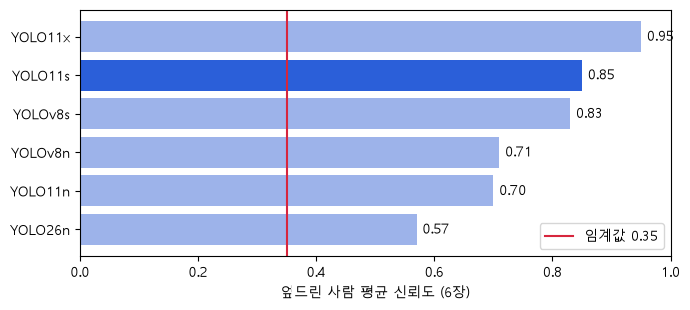

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
t = table.sort_values('평균')
ax.barh(t.index, t['평균'], color=['#2b5fd9' if n == 'YOLO11s' else '#9db3ea' for n in t.index])
ax.axvline(THRESHOLD, color='#d7263d', lw=1.5, label=f'임계값 {THRESHOLD}')
for y, v in enumerate(t['평균']):
    ax.text(v + 0.01, y, f'{v:.2f}', va='center')
ax.set_xlim(0, 1); ax.set_xlabel('엎드린 사람 평균 신뢰도 (6장)'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

### YOLO11s 검출 결과 (MVP에서 쓰는 모델)

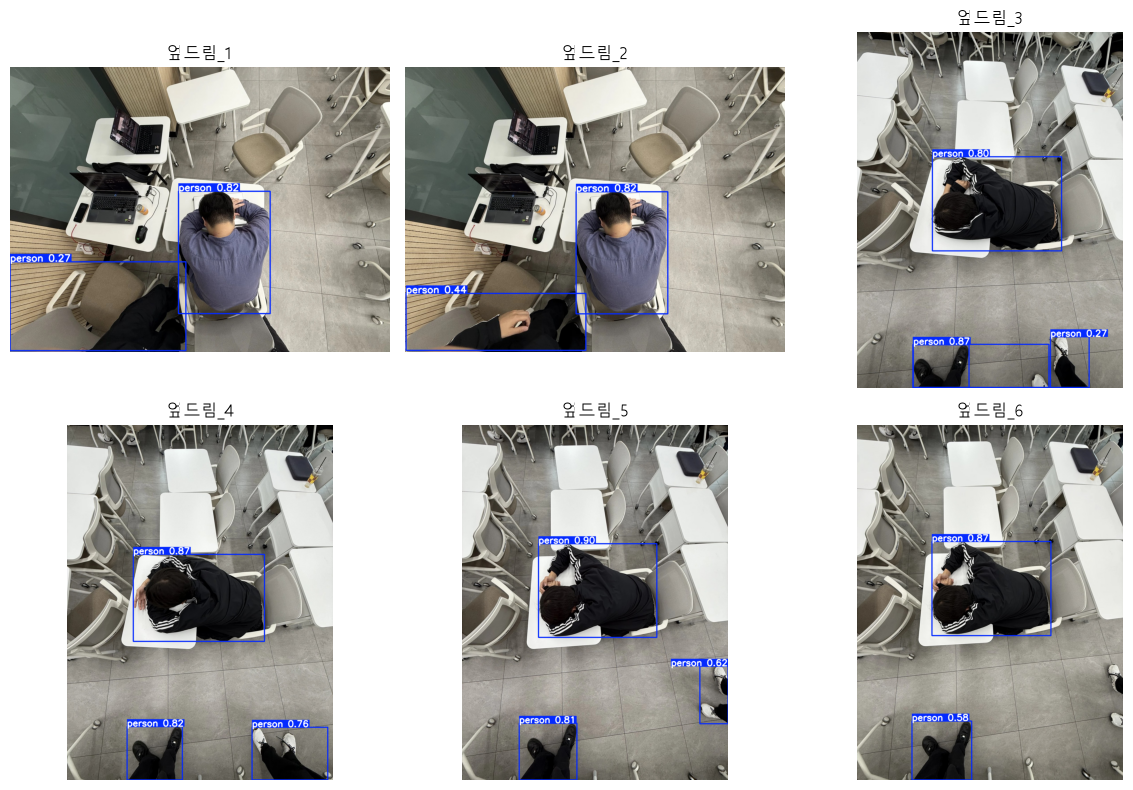

In [5]:
m = YOLO(weights['YOLO11s'])
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, path in zip(axes.flat, IMAGES):
    r = m.predict(cv2.imread(path), imgsz=960, conf=0.25, classes=[0], device=DEVICE, verbose=False)[0]
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); ax.set_title(Path(path).stem); ax.axis('off')
plt.tight_layout(); plt.show()

## 실험 2 · 모델별 리소스

입력 640, 사진 1장 처리 시간(전처리 포함 평균). 판정 기준이 30분이라 룸 하나를 1~2초에 한 장만 봐도 충분하므로,
GPU가 없는 PC나 라즈베리파이에서도 돌아가는지가 중요하다.

In [6]:
im = cv2.imread(IMAGES[0])
res = []
for name in ['YOLO26n', 'YOLO11n', 'YOLO11s', 'YOLO11x']:
    w = weights[name]; m = YOLO(w)
    params = sum(p.numel() for p in m.model.parameters()) / 1e6
    try: flops = get_flops(m.model, 640)
    except Exception: flops = float('nan')
    speed = {}
    for dev, reps in ((DEVICE, 20), ('cpu', 5)):
        for _ in range(3): m.predict(im, imgsz=640, device=dev, verbose=False)
        t0 = time.perf_counter()
        for _ in range(reps): m.predict(im, imgsz=640, device=dev, verbose=False)
        speed[str(dev)] = (time.perf_counter() - t0) / reps * 1000
    size = os.path.getsize(w) / 2**20 if os.path.exists(w) else float('nan')
    res.append({'모델': name, '파라미터(M)': round(params, 1), 'GFLOPs': round(flops, 1), '파일(MB)': round(size, 1),
                'GPU(ms)': round(speed[str(DEVICE)], 1), 'CPU(ms)': round(speed['cpu']),
                '엎드린 사람 평균': table.loc[name, '평균']})
pd.DataFrame(res).set_index('모델')

,파라미터(M),GFLOPs,파일(MB),GPU(ms),CPU(ms),엎드린 사람 평균
모델,,,,,,
YOLO26n,2.6,6.2,5.3,24.2,51,0.57
YOLO11n,2.6,6.7,5.4,18.8,48,0.70
YOLO11s,9.5,21.8,18.4,25.7,94,0.85
YOLO11x,57.0,196.3,109.3,74.0,602,0.95


## 결론

- 걱정과 달리 **엎드린 사람은 6개 모델 모두 6장 전부 검출**했다. 위에서 내려다본 구도라 등·팔·머리가 함께 보이기 때문으로 보인다.
- YOLO11x가 가장 정확하지만 CPU에서 YOLO11s보다 약 6배 느리고 파일이 약 6배 크다.
- **YOLO11s를 기본 모델로 쓴다.** 신뢰도가 충분히 높고 CPU에서도 1장 0.1초 수준이다.
- 라즈베리파이처럼 작은 장비에서 nano 모델을 쓰면 신뢰도가 0.4대까지 떨어질 수 있어, 임계값을 0.3 정도로 낮추는 방안을 함께 검토한다.
- 한계: 사진 6장, 2명뿐이다. 패딩 모자를 쓰고 엎드린 경우, 얼굴이 카메라 쪽인 경우는 추가 촬영으로 확인해야 한다.
- 다음 미팅에서 **모델과 임계값을 팀이 합의**한다.